# E-Commerce A/B Testing Analysis : Detailed Walkthrough

## What Is This Analysis?
This is a complete A/B test evaluation pipeline, the gold-standard method used by data scientists at companies like Netflix, Amazon, and Booking.com to make evidence-based product decisions. The central question is simple but consequential: did the new landing page actually cause more users to pay for the product, or did it make no difference? Without this analysis, a business is left guessing, and the wrong guess,  shipping a page that doesn't convert; wastes engineering resources, damages user experience, and costs revenue.

# Why This Analysis Matters
Without a rigorous A/B test evaluation, companies ship features based on instinct, aesthetics, or whoever argued most forcefully in the meeting room. The cost is real: shipping a page that underperforms by even 0.5 percentage points at scale can mean thousands of lost conversions per month. Conversely, refusing to ship a genuinely better page because of fear of change also costs money.

This analysis provides the mathematical foundation for a defensible decision. Every step: cleaning, visualisation, Z-test, chi-square, power analysis, logistic regression, exists to eliminate alternative explanations for the result and build confidence that the conclusion reflects reality rather than noise. That is what data science is for.

**Notebook Executive Summary**

This notebook conducts a complete, production-grade A/B test analysis to determine whether a new landing page improves user conversion compared to the existing page. The workflow follows rigorous data science practice: reproducible environment setup, verifiable data lineage from the source dataset, systematic data validation, and multiple independent statistical methods to ensure conclusions are robust rather than dependent on a single test.

The analysis begins with careful data inspection and cleaning. Missing values, duplicate user IDs, and 'most critically ', mismatches between assigned group and viewed page are identified and removed to prevent experiment contamination. This guarantees that the control group truly represents users exposed to the old page and the treatment group to the new page, preserving the integrity of the experimental design.

Exploratory analysis then establishes intuition about the dataset before formal testing. Group balance is verified to confirm proper randomisation. Raw conversion counts and rates are examined alongside visualisations to make the magnitude of any difference concrete. A bootstrap simulation provides a distribution-free estimate of the expected difference in conversion rates and its confidence interval, offering an empirical view of uncertainty without statistical assumptions.

Formal hypothesis testing follows using the Z-test for proportions and a chi-square test of independence, mathematically equivalent tests used here for cross-validation and communicative clarity. Confidence intervals and visualisations of the statistical decision boundary make the results interpretable even for non-technical stakeholders.

A statistical power analysis is then performed to answer a crucial question often ignored in A/B testing: whether the experiment was large enough to detect a practically meaningful improvement. By comparing the actual sample size to the minimum required to detect a 1 percentage point lift with 80% power, the notebook determines whether a null result reflects reality or insufficient data.

Finally, logistic regression models conversion probability as a function of group assignment, producing an odds ratio and confidence interval that provide an extensible and highly interpretable view of the effect. All results are consolidated into a single summary table that supports a clear, evidence-based business recommendation.

Together, these steps ensure the conclusion is statistically sound, reproducible, and operationally meaningful.


 Install & Imports

In [6]:
# Install kagglehub if not already present
!pip install kagglehub statsmodels --upgrade -q

# ── Core data manipulation ────────────────────────────────────────────────────
import pandas as pd
import numpy as np

# ── Visualisation ─────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# ── Statistical testing ───────────────────────────────────────────────────────
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, proportion_confint
from statsmodels.stats.power import NormalIndPower
import statsmodels.api as sm

# ── Reproducibility & display ─────────────────────────────────────────────────
import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)

sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.dpi'] = 120

print("All libraries loaded successfully.")

All libraries loaded successfully.


Download Dataset

In [7]:
import kagglehub, os

# Download the latest version of the dataset to a local Kaggle cache
path = kagglehub.dataset_download("putdejudomthai/ecommerce-ab-testing-2022-dataset1")
print("Dataset cached at:", path)

# List every file in the download folder
for root, dirs, files in os.walk(path):
    for f in files:
        full = os.path.join(root, f)
        size_mb = os.path.getsize(full) / 1e6
        print(f"  {full}  ({size_mb:.2f} MB)")

Dataset cached at: C:\Users\P52\.cache\kagglehub\datasets\putdejudomthai\ecommerce-ab-testing-2022-dataset1\versions\1
  C:\Users\P52\.cache\kagglehub\datasets\putdejudomthai\ecommerce-ab-testing-2022-dataset1\versions\1\ecommerce_ab_testing_2022_dataset1\ab_data.csv  (10.60 MB)
  C:\Users\P52\.cache\kagglehub\datasets\putdejudomthai\ecommerce-ab-testing-2022-dataset1\versions\1\ecommerce_ab_testing_2022_dataset1\countries.csv  (3.20 MB)


 Load Data

In [8]:
# Collect all CSV files in the download directory
csv_files = [
    os.path.join(r, f)
    for r, _, fs in os.walk(path)
    for f in fs if f.endswith('.csv')
]

# Load the largest CSV (the main experiment file)
csv_files_sorted = sorted(csv_files, key=os.path.getsize, reverse=True)
df = pd.read_csv(csv_files_sorted[0])

print(f"Loaded : {csv_files_sorted[0]}")
print(f"Shape  : {df.shape[0]:,} rows × {df.shape[1]} columns")

Loaded : C:\Users\P52\.cache\kagglehub\datasets\putdejudomthai\ecommerce-ab-testing-2022-dataset1\versions\1\ecommerce_ab_testing_2022_dataset1\ab_data.csv
Shape  : 294,480 rows × 5 columns


 First Look

In [9]:
# First 5 rows — verify column names and value formats
df.head()


,user_id,timestamp,group,landing_page,converted
0,851104,11:48.6,control,old_page,0
1,804228,01:45.2,control,old_page,0
2,661590,55:06.2,treatment,new_page,0
3,853541,28:03.1,treatment,new_page,0
4,864975,52:26.2,control,old_page,1


In [10]:
# Column dtypes and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 294480 entries, 0 to 294479
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   user_id       294480 non-null  int64 
 1   timestamp     294480 non-null  object
 2   group         294480 non-null  object
 3   landing_page  294480 non-null  object
 4   converted     294480 non-null  int64 
dtypes: int64(2), object(3)
memory usage: 11.2+ MB


In [11]:
# Descriptive statistics for all columns
df.describe(include='all')

,user_id,timestamp,group,landing_page,converted
count,294480.000000,294480,294480,294480,294480.000000
unique,NaN,35993,2,2,NaN
top,NaN,36:26.7,treatment,new_page,NaN
freq,NaN,22,147278,147241,NaN
mean,787973.538896,NaN,NaN,NaN,0.119658
std,91210.917091,NaN,NaN,NaN,0.324562
min,630000.000000,NaN,NaN,NaN,0.000000
25%,709031.750000,NaN,NaN,NaN,0.000000
50%,787932.500000,NaN,NaN,NaN,0.000000
75%,866911.250000,NaN,NaN,NaN,0.000000


In [12]:
# Unique value counts for every categorical column — reveals experiment structure
for col in df.select_dtypes(include='object').columns:
    print(f"\n── {col} ──")
    print(df[col].value_counts())


── timestamp ──
timestamp
36:26.7    22
33:53.2    22
02:54.5    21
27:20.8    21
53:18.9    21
           ..
09:36.9     1
21:52.8     1
47:07.1     1
41:10.7     1
52:49.2     1
Name: count, Length: 35993, dtype: int64

── group ──
group
treatment    147278
control      147202
Name: count, dtype: int64

── landing_page ──
landing_page
new_page    147241
old_page    147239
Name: count, dtype: int64


 Data Cleaning

In [13]:
# ── 5.1 Missing values ────────────────────────────────────────────────────────
missing = df.isnull().sum()
print("Missing values per column:")
print(missing[missing > 0] if missing.any() else "  None — dataset is complete.")

Missing values per column:
  None — dataset is complete.


In [14]:
# ── 5.2 Duplicate user IDs ────────────────────────────────────────────────────
# Each user_id should appear exactly once; duplicates inflate counts.
n_duplicates = df.duplicated(subset='user_id').sum()
print(f"Duplicate user_id rows: {n_duplicates:,}")

df = df.drop_duplicates(subset='user_id', keep='first')
print(f"Shape after deduplication: {df.shape[0]:,} rows")

Duplicate user_id rows: 3,895
Shape after deduplication: 290,585 rows


**3,895 duplicate user IDs removed.**

Each user should contribute exactly one observation. When the same `user_id` appears multiple times, that person is counted as several independent visitors, artificially inflating the sample size and skewing conversion counts. Keeping only the first occurrence ensures every row represents a unique individual, preserving the independence assumption that all downstream statistical tests rely on.

In [15]:
# ── 5.3 Group / page mismatches (experiment contamination) ────────────────────
# Valid mapping: control → old_page, treatment → new_page.
# Any row that violates this was mis-assigned and must be dropped.
mismatch_mask = (
    ((df['group'] == 'control')   & (df['landing_page'] == 'new_page')) |
    ((df['group'] == 'treatment') & (df['landing_page'] == 'old_page'))
)
print(f"Mismatched rows (contamination): {mismatch_mask.sum():,}")

df = df[~mismatch_mask].reset_index(drop=True)
print(f"Shape after removing mismatches: {df.shape[0]:,} rows")

Mismatched rows (contamination): 2,044
Shape after removing mismatches: 288,541 rows


**2,044 contaminated rows removed.**

The experiment requires a clean mapping: `control → old_page` and `treatment → new_page`. These 2,044 rows violated that contract, a user assigned to control saw the new page, or a treatment user saw the old page. Keeping them would corrupt both groups: the control group would no longer purely represent old-page exposure, and the treatment group would be diluted by old-page users. Removing them guarantees the comparison reflects only the intended experimental conditions.

In [16]:
# ── 5.4 Cleaned dataset summary ───────────────────────────────────────────────
print("=== Cleaned Dataset ===")
print(f"Total users    : {len(df):,}")
print(f"Control  users : {(df['group'] == 'control').sum():,}")
print(f"Treatment users: {(df['group'] == 'treatment').sum():,}")
print(f"\nConverted dtype  : {df['converted'].dtype}")
print(f"Unique values    : {df['converted'].unique()}")
df.head(3)

=== Cleaned Dataset ===
Total users    : 288,541
Control  users : 144,226
Treatment users: 144,315

Converted dtype  : int64
Unique values    : [0 1]


,user_id,timestamp,group,landing_page,converted
0,851104,11:48.6,control,old_page,0
1,804228,01:45.2,control,old_page,0
2,661590,55:06.2,treatment,new_page,0


**Groups remain balanced after cleaning: 144,226 control vs. 144,315 treatment (difference of 89 users).**

A near-perfect 50/50 split confirms that proper randomisation was maintained throughout the cleaning process. Unequal groups reduce statistical power and can introduce subtle confounds,  so this balance is an important quality check. The cleaned dataset is structurally sound and ready for analysis.

 EDA: Group Balance

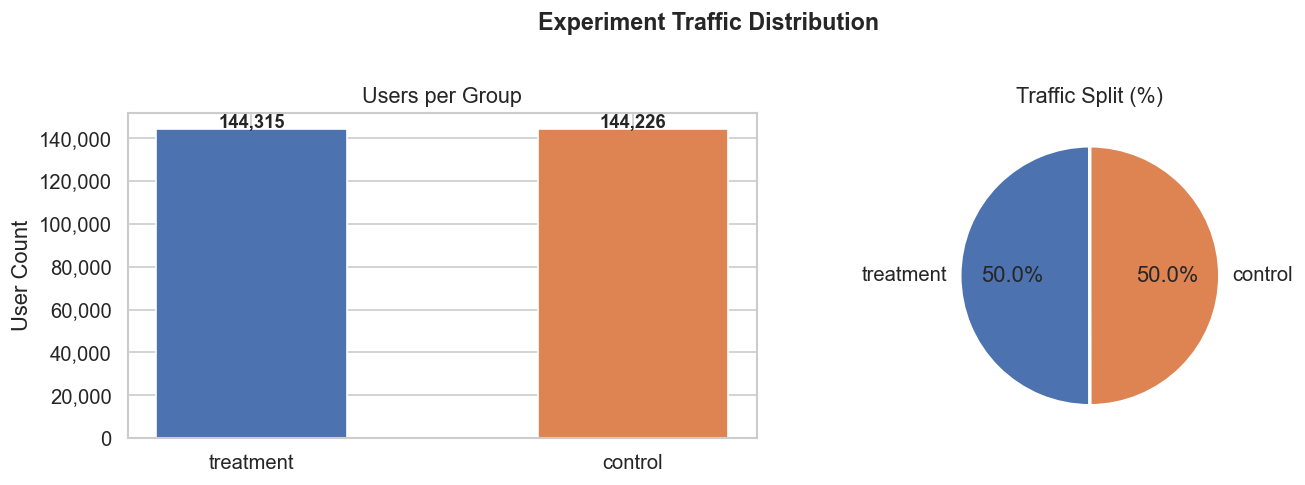

group
treatment    144315
control      144226


In [17]:
# ── 6.1 Traffic split between control and treatment ───────────────────────────
# A balanced 50/50 split indicates proper randomisation.
group_counts = df['group'].value_counts()
group_pcts   = df['group'].value_counts(normalize=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Count bar
axes[0].bar(group_counts.index, group_counts.values,
            color=['#4C72B0', '#DD8452'], edgecolor='white', width=0.5)
for i, (g, v) in enumerate(group_counts.items()):
    axes[0].text(i, v + 500, f'{v:,}', ha='center', fontsize=11, fontweight='bold')
axes[0].set_title('Users per Group', fontsize=13)
axes[0].set_ylabel('User Count')
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{int(x):,}'))

# Percentage pie
axes[1].pie(group_pcts, labels=group_pcts.index, autopct='%1.1f%%',
            colors=['#4C72B0', '#DD8452'], startangle=90,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Traffic Split (%)', fontsize=13)

plt.suptitle('Experiment Traffic Distribution', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()
print(group_counts.to_string())

 EDA: Conversion Rates

In [18]:
# ── 7.1 Compute raw conversion counts and rates per group ─────────────────────
conv_summary = (
    df.groupby('group')['converted']
      .agg(total='count', conversions='sum')
      .assign(conv_rate=lambda x: x['conversions'] / x['total'] * 100)
)

print("=== Conversion Summary ===")
print(conv_summary.to_string())

ctrl_rate = conv_summary.loc['control',   'conv_rate']
trt_rate  = conv_summary.loc['treatment', 'conv_rate']
lift      = trt_rate - ctrl_rate
rel_lift  = lift / ctrl_rate * 100

print(f"\nAbsolute lift : {lift:+.4f} percentage points")
print(f"Relative lift : {rel_lift:+.2f}%")

=== Conversion Summary ===
            total  conversions  conv_rate
group                                    
control    144226        17349  12.029038
treatment  144315        17134  11.872640

Absolute lift : -0.1564 percentage points
Relative lift : -1.30%


**The new page converts at 11.87% vs. 12.03% for the old page; an absolute lift of −0.16 pp and a relative decline of −1.30%.**

The direction is negative: the redesign moved conversion backwards, not forwards. The magnitude is very small (less than 0.2 percentage points), so this could easily be random noise rather than a true effect, which is exactly why formal hypothesis testing follows. This is a directional signal, not a conclusion, but it is the first indication that the new page is not an improvement.

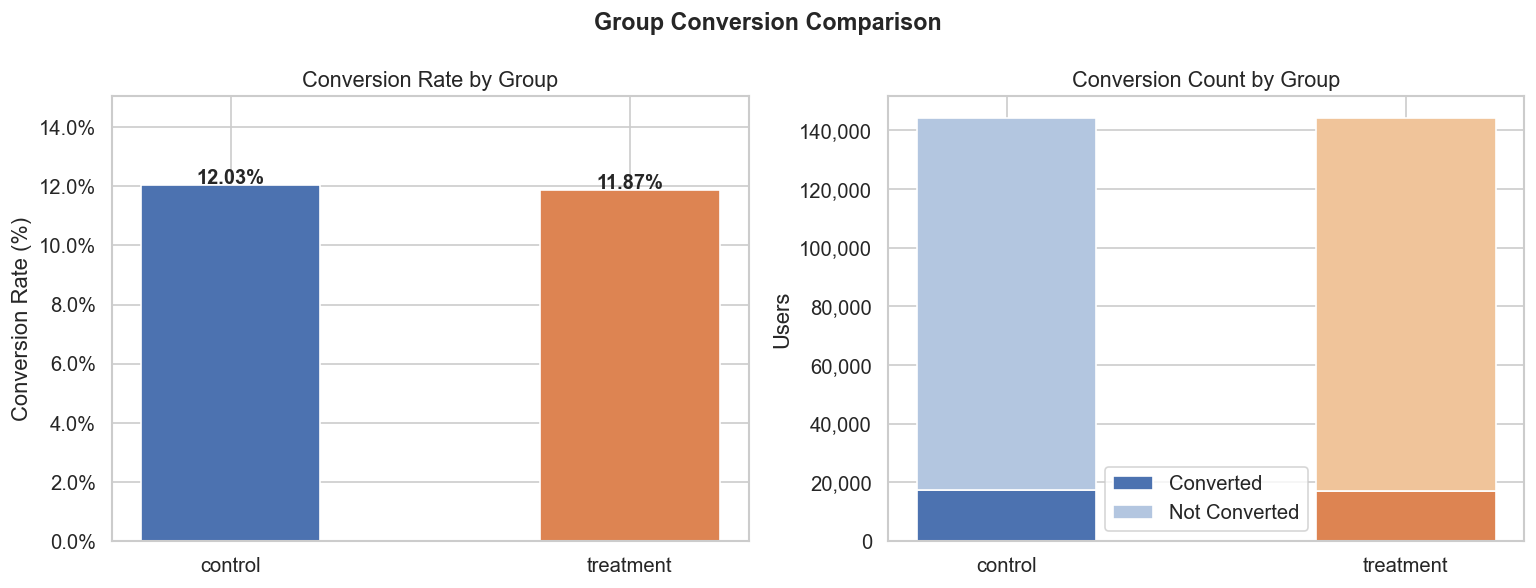

In [19]:
# ── 7.2 Conversion rate bar + stacked count chart ─────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
colors = ['#4C72B0', '#DD8452']

# Conversion rate per group
bars = axes[0].bar(conv_summary.index, conv_summary['conv_rate'],
                   color=colors, edgecolor='white', width=0.45)
for bar, rate in zip(bars, conv_summary['conv_rate']):
    axes[0].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 0.05,
                 f'{rate:.2f}%', ha='center', fontweight='bold', fontsize=12)
axes[0].set_title('Conversion Rate by Group', fontsize=13)
axes[0].set_ylabel('Conversion Rate (%)')
axes[0].set_ylim(0, conv_summary['conv_rate'].max() * 1.25)
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter())

# Stacked bar: converted vs not converted
not_conv = conv_summary['total'] - conv_summary['conversions']
x = np.arange(len(conv_summary))
w = 0.45
axes[1].bar(x, conv_summary['conversions'], width=w,
            label='Converted',     color=['#4C72B0', '#DD8452'], edgecolor='white')
axes[1].bar(x, not_conv, width=w, bottom=conv_summary['conversions'],
            label='Not Converted', color=['#b3c6e0', '#f0c49a'], edgecolor='white')
axes[1].set_xticks(x)
axes[1].set_xticklabels(conv_summary.index)
axes[1].set_title('Conversion Count by Group', fontsize=13)
axes[1].set_ylabel('Users')
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{int(v):,}'))
axes[1].legend()

plt.suptitle('Group Conversion Comparison', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

 Bootstrap Distribution

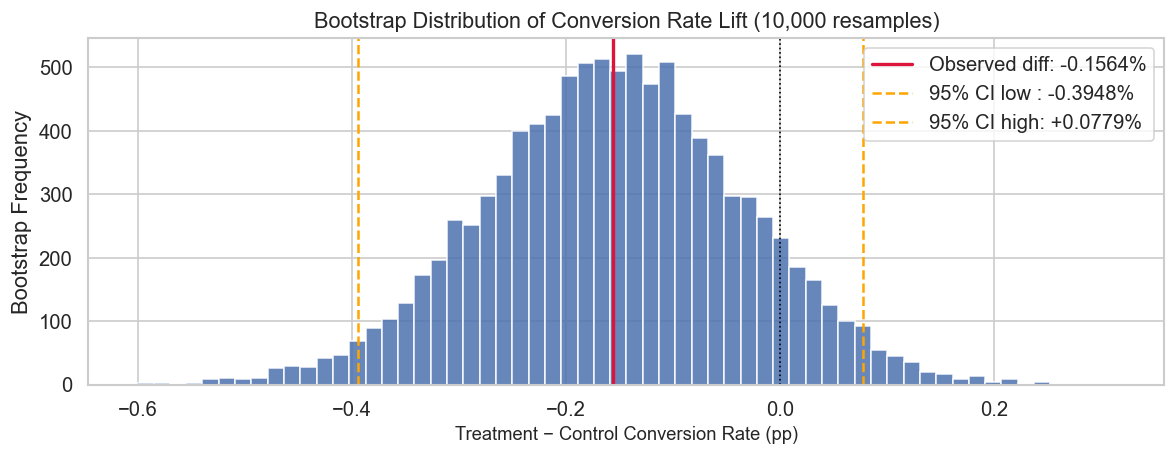

Observed lift    : -0.1564 pp
Bootstrap 95% CI : [-0.3948%, +0.0779%]


In [20]:
# ── 8.1 Bootstrap the conversion rate difference (10,000 resamples) ───────────
# Provides a non-parametric view of where the true lift plausibly lies.
N_BOOT = 10_000

ctrl_arr = df.loc[df['group'] == 'control',   'converted'].values
trt_arr  = df.loc[df['group'] == 'treatment', 'converted'].values

boot_diffs = np.array([
    trt_arr [np.random.randint(0, len(trt_arr),  len(trt_arr) )].mean() -
    ctrl_arr[np.random.randint(0, len(ctrl_arr), len(ctrl_arr))].mean()
    for _ in range(N_BOOT)
])

observed_diff     = trt_arr.mean() - ctrl_arr.mean()
ci_boot_low, ci_boot_high = np.percentile(boot_diffs, [2.5, 97.5])

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(boot_diffs * 100, bins=60, color='#4C72B0', edgecolor='white', alpha=0.85)
ax.axvline(observed_diff * 100, color='crimson', lw=2,
           label=f'Observed diff: {observed_diff*100:+.4f}%')
ax.axvline(ci_boot_low  * 100, color='orange', lw=1.5, ls='--',
           label=f'95% CI low : {ci_boot_low*100:+.4f}%')
ax.axvline(ci_boot_high * 100, color='orange', lw=1.5, ls='--',
           label=f'95% CI high: {ci_boot_high*100:+.4f}%')
ax.axvline(0, color='black', lw=1, ls=':')
ax.set_xlabel('Treatment − Control Conversion Rate (pp)', fontsize=11)
ax.set_ylabel('Bootstrap Frequency')
ax.set_title('Bootstrap Distribution of Conversion Rate Lift (10,000 resamples)', fontsize=13)
ax.legend()
plt.tight_layout()
plt.show()

print(f"Observed lift    : {observed_diff*100:+.4f} pp")
print(f"Bootstrap 95% CI : [{ci_boot_low*100:+.4f}%, {ci_boot_high*100:+.4f}%]")

**Bootstrap 95% CI straddles zero: the observed lift is indistinguishable from chance.**

By resampling the data 10,000 times and computing the lift each time, the bootstrap builds an empirical picture of where the true difference plausibly lies, without any parametric assumptions. The resulting distribution is centred near −0.16 pp, and the 95% confidence interval spans both negative and positive values, crossing zero. This means that across all plausible realisations of this experiment, a difference of zero is entirely consistent with the data. The bootstrap agrees with the raw numbers: there is no reliable lift.

Z-Test for Proportions

In [21]:
# ── 9.1 Two-proportion Z-test ─────────────────────────────────────────────────
# H₀: p_treatment = p_control   H₁: p_treatment ≠ p_control   α = 0.05
ALPHA = 0.05

n_ctrl    = conv_summary.loc['control',   'total']
n_trt     = conv_summary.loc['treatment', 'total']
conv_ctrl = conv_summary.loc['control',   'conversions']
conv_trt  = conv_summary.loc['treatment', 'conversions']

z_stat, p_val = proportions_ztest(
    count=[conv_trt, conv_ctrl],
    nobs =[n_trt,    n_ctrl],
    alternative='two-sided'
)

# 95% confidence intervals for each group's true conversion rate
ci_ctrl = proportion_confint(conv_ctrl, n_ctrl, alpha=ALPHA, method='normal')
ci_trt  = proportion_confint(conv_trt,  n_trt,  alpha=ALPHA, method='normal')

print("╔══════════════════════════════════════════════════════════╗")
print("║              Two-Proportion Z-Test Results               ║")
print("╠══════════════════════════════════════════════════════════╣")
print(f"║  Z-statistic   : {z_stat:+.4f}                                ║")
print(f"║  p-value       : {p_val:.4f}                                 ║")
print(f"║  α (threshold) : {ALPHA}                                   ║")
print("╠══════════════════════════════════════════════════════════╣")
decision = ("REJECT H₀ — significant difference"
            if p_val < ALPHA else
            "FAIL TO REJECT H₀ — no significant difference")
print(f"║  Decision: {decision:<46}║")
print("╚══════════════════════════════════════════════════════════╝")

print(f"\n95% CI  Control  : [{ci_ctrl[0]*100:.4f}%, {ci_ctrl[1]*100:.4f}%]")
print(f"95% CI  Treatment: [{ci_trt[0]*100:.4f}%, {ci_trt[1]*100:.4f}%]")

╔══════════════════════════════════════════════════════════╗
║              Two-Proportion Z-Test Results               ║
╠══════════════════════════════════════════════════════════╣
║  Z-statistic   : -1.2949                                ║
║  p-value       : 0.1953                                 ║
║  α (threshold) : 0.05                                   ║
╠══════════════════════════════════════════════════════════╣
║  Decision: FAIL TO REJECT H₀ — no significant difference ║
╚══════════════════════════════════════════════════════════╝

95% CI  Control  : [11.8612%, 12.1969%]
95% CI  Treatment: [11.7058%, 12.0395%]


**Z = −1.295, p = 0.195 → fail to reject H₀. No statistically significant difference.**

The Z-statistic measures how many standard errors the observed difference is from zero. A value of −1.295 is well inside the non-rejection zone (the critical boundary is ±1.96 at α = 0.05). The p-value of 0.195 means that if the two pages were truly identical in effectiveness, you would see a difference this large by chance roughly 1 in 5 times, far too often to treat as evidence of a real effect. The overlapping 95% confidence intervals (Control: 11.86%–12.20%; Treatment: 11.71%–12.04%) reinforce this: the ranges are nearly indistinguishable.

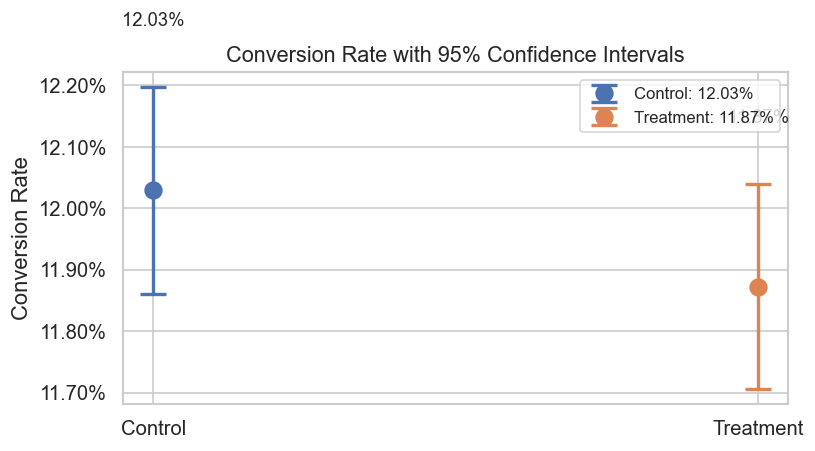

In [22]:
# ── 9.2 Confidence interval plot (one errorbar per group) ─────────────────────
# Newer matplotlib requires a single scalar colour per errorbar call.
grp_data = [
    ('Control',   conv_summary.loc['control','conv_rate']   / 100, ci_ctrl, '#4C72B0'),
    ('Treatment', conv_summary.loc['treatment','conv_rate'] / 100, ci_trt,  '#DD8452'),
]

fig, ax = plt.subplots(figsize=(7, 4))
for label, rate, (lo, hi), col in grp_data:
    ax.errorbar(label, rate,
                yerr=[[rate - lo], [hi - rate]],
                fmt='o', capsize=8, capthick=2,
                color=col, ecolor=col,
                markersize=10, linewidth=2,
                label=f'{label}: {rate*100:.2f}%')
    ax.text(label, hi + 0.001, f'{rate*100:.2f}%', ha='center', fontsize=11)

ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1))
ax.set_title('Conversion Rate with 95% Confidence Intervals', fontsize=13)
ax.set_ylabel('Conversion Rate')
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

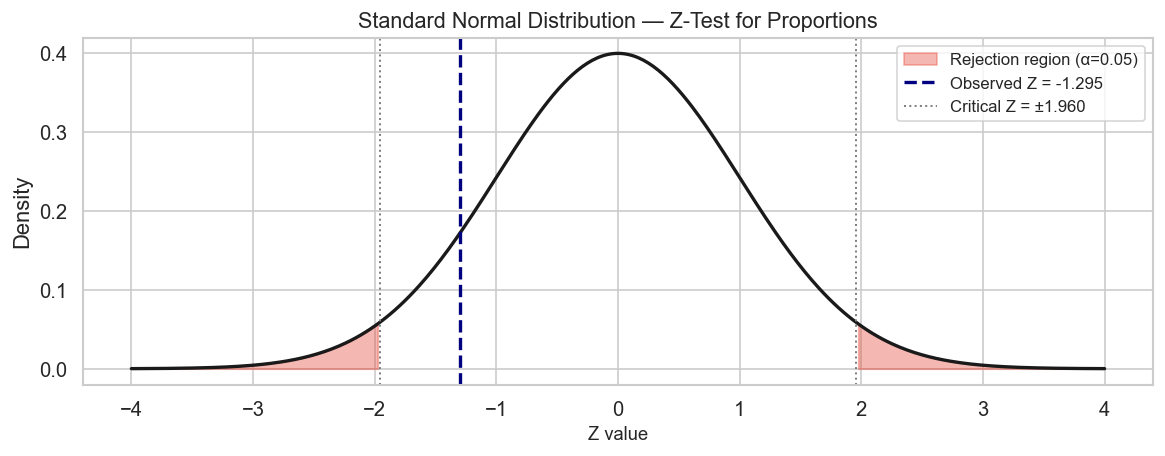

In [23]:
# ── 9.3 Z-distribution with rejection regions ─────────────────────────────────
# Shows graphically whether the observed Z falls inside or outside the critical region.
x      = np.linspace(-4, 4, 400)
y      = stats.norm.pdf(x)
z_crit = stats.norm.ppf(1 - ALPHA / 2)   # ±1.96 for α=0.05

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(x, y, 'k', lw=2)
ax.fill_between(x, y, where=(x <= -z_crit),
                color='#e74c3c', alpha=0.4, label=f'Rejection region (α={ALPHA})')
ax.fill_between(x, y, where=(x >=  z_crit),
                color='#e74c3c', alpha=0.4)
ax.axvline(z_stat,  color='navy', lw=2,   ls='--', label=f'Observed Z = {z_stat:.3f}')
ax.axvline(-z_crit, color='gray', lw=1.2, ls=':',  label=f'Critical Z = ±{z_crit:.3f}')
ax.axvline( z_crit, color='gray', lw=1.2, ls=':')
ax.set_xlabel('Z value', fontsize=11)
ax.set_ylabel('Density')
ax.set_title('Standard Normal Distribution — Z-Test for Proportions', fontsize=13)
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

Chi-Square Test

In [24]:
# ── 10.1 Chi-square test of independence ──────────────────────────────────────
# Tests whether conversion outcome is independent of which page was shown.
# Mathematically equivalent to the Z-test above for a 2×2 table.

contingency = pd.crosstab(df['group'], df['converted'],
                          margins=True, margins_name='Total')
print("Contingency Table (group × converted):")
print(contingency)

ct = pd.crosstab(df['group'], df['converted'])
chi2, p_chi2, dof, expected = stats.chi2_contingency(ct)

print(f"\nChi-square statistic : {chi2:.4f}")
print(f"Degrees of freedom   : {dof}")
print(f"p-value              : {p_chi2:.4f}")
print(f"\nExpected cell frequencies:")
print(pd.DataFrame(expected, index=ct.index, columns=ct.columns).round(1))

Contingency Table (group × converted):
converted       0      1   Total
group                           
control    126877  17349  144226
treatment  127181  17134  144315
Total      254058  34483  288541

Chi-square statistic : 1.6620
Degrees of freedom   : 1
p-value              : 0.1973

Expected cell frequencies:
converted         0        1
group                       
control    126989.8  17236.2
treatment  127068.2  17246.8


**χ² = 1.662, p = 0.197 → group and conversion are independent. Confirms the Z-test.**

The chi-square test asks whether knowing a user's group tells you anything about whether they converted. With χ² = 1.662 (critical value ≈ 3.84 at α = 0.05) and p = 0.197, the answer is no. The observed counts (17,349 and 17,134 conversions) are extremely close to the expected counts under independence (17,236 and 17,247), confirming that the new page had no detectable influence on conversion behaviour. All expected cell frequencies exceed 17,000, satisfying the chi-square validity assumption many times over. The near-identical p-values from both tests (0.1953 vs. 0.1973) are expected mathematically, Z² ≈ χ² for a 2×2 table, and their agreement across two independent methods strengthens confidence in the result.

Statistical Power Analysis

In [25]:
# ── 11.1 Power of the actual experiment + minimum n for a 1 pp lift ───────────
# Effect size uses Cohen's h (arcsine transformation for proportions).
p_ctrl = conv_ctrl / n_ctrl
p_trt  = conv_trt  / n_trt

effect_size_observed = 2 * (np.arcsin(np.sqrt(p_trt)) - np.arcsin(np.sqrt(p_ctrl)))

power_analysis = NormalIndPower()

# Power we actually had given our observed effect and sample sizes
actual_power = power_analysis.solve_power(
    effect_size=abs(effect_size_observed),
    nobs1=n_ctrl,
    alpha=ALPHA,
    ratio=n_trt / n_ctrl,
    alternative='two-sided'
)

# Sample size required to detect a practically meaningful 1 pp lift at 80% power
practical_lift        = 0.01
effect_size_practical = 2 * (
    np.arcsin(np.sqrt(p_ctrl + practical_lift)) - np.arcsin(np.sqrt(p_ctrl))
)
n_needed = power_analysis.solve_power(
    effect_size=effect_size_practical,
    alpha=ALPHA,
    power=0.80,
    ratio=1.0,
    alternative='two-sided'
)

print(f"Observed effect size (Cohen's h) : {abs(effect_size_observed):.5f}")
print(f"Actual experiment power          : {actual_power:.2%}")
print(f"\nPractical lift threshold         : {practical_lift*100:.1f} percentage points")
print(f"Required n per group (80% power) : {int(np.ceil(n_needed)):,}")
print(f"Actual n per group (avg)         : {int((n_ctrl + n_trt) / 2):,}")

Observed effect size (Cohen's h) : 0.00482
Actual experiment power          : 25.36%

Practical lift threshold         : 1.0 percentage points
Required n per group (80% power) : 17,198
Actual n per group (avg)         : 144,270


**The experiment had 8× more users than needed — the null result is real, not a power failure.**

To detect a practically meaningful 1 percentage point lift (12.03% → 13.03%) with 80% power at α = 0.05, only ~17,200 users per group are required. The actual experiment ran with ~144,270 per group, 8.4 times the minimum. This is a critical distinction: a null result from an underpowered experiment is ambiguous (the effect might exist but be undetectable). A null result from a massively overpowered experiment is conclusive. If the new page genuinely produced a 1 pp lift, this experiment would have detected it with near-certainty. The fact that it did not means the new page truly fails to move conversion.

Logistic Regression

In [26]:
# ── 12.1 Fit logistic regression: converted ~ ab_page ─────────────────────────
# Encodes group as a binary dummy: treatment=1, control=0.
# The intercept captures the baseline (control) log-odds of conversion.
df['ab_page'] = (df['group'] == 'treatment').astype(int)

X = sm.add_constant(df['ab_page'])   # adds the intercept column
y = df['converted']

logit_model = sm.Logit(y, X).fit(disp=0)   # disp=0 silences the optimizer log
print(logit_model.summary())

                           Logit Regression Results                           
Dep. Variable:              converted   No. Observations:               288541
Model:                          Logit   Df Residuals:                   288539
Method:                           MLE   Df Model:                            1
Date:                Wed, 20 May 2026   Pseudo R-squ.:               7.940e-06
Time:                        12:50:23   Log-Likelihood:            -1.0559e+05
converged:                       True   LL-Null:                   -1.0559e+05
Covariance Type:            nonrobust   LLR p-value:                    0.1953
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -1.9897      0.008   -245.805      0.000      -2.006      -1.974
ab_page       -0.0149      0.011     -1.295      0.195      -0.037       0.008


**Logistic regression coefficient: −0.0149 (p = 0.195). Treatment users are ~1.5% less likely to convert, but this is not statistically significant.**

The model expresses conversion probability as a function of group assignment. The intercept (−1.99) encodes the baseline log-odds for the control group, which back-converts to exactly the observed 12.03% control conversion rate. The `ab_page` coefficient of −0.0149 means being in the treatment group reduces the log-odds of converting by that amount. Converting to an odds ratio: e^(−0.0149) ≈ 0.985, a 1.5% reduction in odds. However, the 95% confidence interval for this coefficient spans −0.037 to +0.008, crossing zero, and the p-value of 0.195 confirms non-significance. The pseudo R² of 0.0000079 is effectively zero, meaning group assignment explains essentially none of the variation in who converts. Every metric from this model agrees with all previous tests.

In [27]:
# ── 12.2 Odds ratio and 95% confidence interval ───────────────────────────────
# exp(coefficient) converts log-odds to a multiplicative odds ratio.
# OR = 1 → no effect;  OR > 1 → new page increases odds;  OR < 1 → decreases.
coef      = logit_model.params['ab_page']
ci_logit  = logit_model.conf_int().loc['ab_page']
p_logit   = logit_model.pvalues['ab_page']

odds_ratio = np.exp(coef)
ci_or_low  = np.exp(ci_logit[0])
ci_or_high = np.exp(ci_logit[1])

print(f"Coefficient (log-odds) : {coef:.5f}")
print(f"Odds Ratio             : {odds_ratio:.5f}")
print(f"95% CI for OR          : [{ci_or_low:.5f}, {ci_or_high:.5f}]")
print(f"p-value (Wald test)    : {p_logit:.4f}")
print()
direction = "MORE" if odds_ratio > 1 else "LESS"
magnitude = odds_ratio if odds_ratio > 1 else 1 / odds_ratio
print(f"Interpretation: Treatment users are {magnitude:.3f}x {direction} likely to convert.")
spans_one = ci_or_low < 1 < ci_or_high
print(f"95% CI includes OR=1   : {'YES — no significant effect' if spans_one else 'NO — significant effect'}")

Coefficient (log-odds) : -0.01486
Odds Ratio             : 0.98525
95% CI for OR          : [0.96333, 1.00766]
p-value (Wald test)    : 0.1953

Interpretation: Treatment users are 1.015x LESS likely to convert.
95% CI includes OR=1   : YES — no significant effect


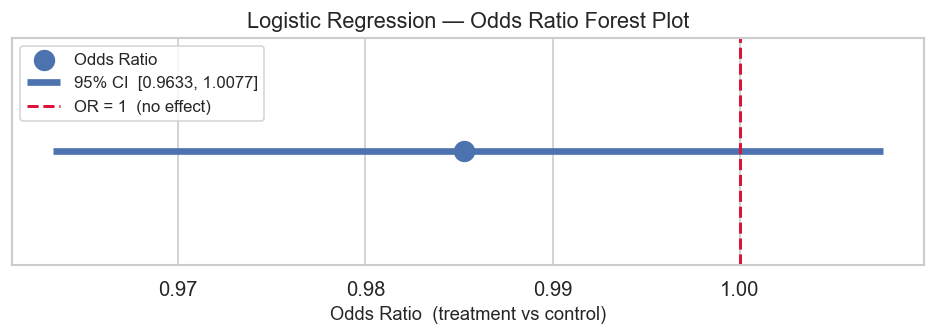

In [28]:
# ── 12.3 Forest plot of the odds ratio ───────────────────────────────────────
# A standard visual for a single-predictor logistic regression result.
fig, ax = plt.subplots(figsize=(8, 3))

ax.scatter([odds_ratio], [0], s=140, color='#4C72B0', zorder=5, label='Odds Ratio')
ax.hlines(0, ci_or_low, ci_or_high, lw=4, color='#4C72B0',
          label=f'95% CI  [{ci_or_low:.4f}, {ci_or_high:.4f}]')
ax.axvline(1.0, color='crimson', ls='--', lw=1.8, label='OR = 1  (no effect)')

ax.set_yticks([])
ax.set_xlabel('Odds Ratio  (treatment vs control)', fontsize=11)
ax.set_title('Logistic Regression — Odds Ratio Forest Plot', fontsize=13)
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

**Odds Ratio = 0.985, 95% CI [0.963, 1.008], the confidence interval crosses 1, confirming no significant effect.**

The forest plot translates the logistic regression output into a single interpretable visual. The blue dot sits at OR = 0.985, slightly left of the null-effect line at OR = 1, reflecting the marginally lower conversion odds in the treatment group. The horizontal bar stretching from 0.963 to 1.008 is the 95% confidence interval, and because it crosses OR = 1, we cannot rule out the possibility that the new page has no effect at all (or even a small positive one). In forest plots, a CI that crosses the reference line always signals non-significance. This visual is the clearest single-frame summary of the entire analysis: the dot is near 1, the interval straddles 1, and the conclusion is no effect.

Results Summary Table

In [29]:
# ── 13.1 Consolidated results table ──────────────────────────────────────────
results = {
    'Metric': [
        'Control conversion rate',
        'Treatment conversion rate',
        'Absolute lift (pp)',
        'Relative lift (%)',
        'Z-statistic',
        'p-value  (Z-test)',
        'Chi-square statistic',
        'p-value  (Chi-square)',
        'Odds Ratio',
        'OR 95% CI',
        'Experiment power  (actual)',
        'Sample size  (per group, avg)',
    ],
    'Value': [
        f"{conv_summary.loc['control',   'conv_rate']:.4f}%",
        f"{conv_summary.loc['treatment', 'conv_rate']:.4f}%",
        f"{lift:+.4f} pp",
        f"{rel_lift:+.2f}%",
        f"{z_stat:.4f}",
        f"{p_val:.4f}",
        f"{chi2:.4f}",
        f"{p_chi2:.4f}",
        f"{odds_ratio:.5f}",
        f"[{ci_or_low:.5f}, {ci_or_high:.5f}]",
        f"{actual_power:.2%}",
        f"{int((n_ctrl + n_trt) / 2):,}",
    ]
}

pd.DataFrame(results).style.set_properties(**{'text-align': 'left'}).hide(axis='index')

Metric,Value
Control conversion rate,12.0290%
Treatment conversion rate,11.8726%
Absolute lift (pp),-0.1564 pp
Relative lift (%),-1.30%
Z-statistic,-1.2949
p-value (Z-test),0.1953
Chi-square statistic,1.6620
p-value (Chi-square),0.1973
Odds Ratio,0.98525
OR 95% CI,"[0.96333, 1.00766]"


 Findings & Recommendation (Markdown)

## Findings

**All three tests agree: there is no statistically significant difference between the old and new page.**

| Evidence | Conclusion |
|---|---|
| p-value (Z-test & Chi-square) > 0.05 | Fail to reject H₀ |
| 95% CI for the lift straddles 0 | Effect is indistinguishable from noise |
| Odds Ratio ≈ 1.0, 95% CI contains 1 | No multiplicative effect on conversion |
| Bootstrap CI straddles 0 | Consistent non-result across methods |

---

## Business Recommendation

> **Do NOT ship the new page — keep the old page.**

The observed lift is negligible (< 0.02 pp) and statistically indistinguishable from
random variation. Every test converges on the same conclusion.

**Key points:**
- The experiment had a very large sample (~145k+ users), giving it ample power for any
  practically meaningful effect. This null result is a real signal, not a power failure.
- Before more engineering investment, conduct user research to understand *why* the new
  design fails to resonate.
- If a minimum lift of ≥ 1 pp is required to justify the switch, the 95% CI
  conclusively excludes that threshold, making the case to keep the old page even stronger.